# Análise de Dados do Brasileirão

## Objetivo

Investigar padrões históricos do Campeonato Brasileiro de Futebol,
analisando a quantidade de gols, a distribuição dos resultados
e a vantagem de jogar em casa.

## Base de dados

A análise utiliza o arquivo `campeonato-brasileiro-full.csv`,
que contém informações sobre partidas, equipes, placares,
datas e estádios.


## 1. Carregamento e Preparação dos Dados

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [78]:
caminho = "../data/raw/campeonato-brasileiro-full.csv"
df = pd.read_csv(caminho)
df.head()

,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado,arrecadacao
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ,NaN
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS,NaN
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR,NaN
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA,NaN
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP,NaN


In [79]:
df.shape

(9165, 17)

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9165 entries, 0 to 9164
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  9165 non-null   int64  
 1   rodata              9165 non-null   int64  
 2   data                9165 non-null   str    
 3   hora                9165 non-null   str    
 4   mandante            9165 non-null   str    
 5   visitante           9165 non-null   str    
 6   formacao_mandante   4190 non-null   str    
 7   formacao_visitante  4190 non-null   str    
 8   tecnico_mandante    4555 non-null   str    
 9   tecnico_visitante   4555 non-null   str    
 10  vencedor            9165 non-null   str    
 11  arena               9165 non-null   str    
 12  mandante_Placar     9165 non-null   int64  
 13  visitante_Placar    9165 non-null   int64  
 14  mandante_Estado     9165 non-null   str    
 15  visitante_Estado    9165 non-null   str    
 16  arrecadacao      

In [81]:
df.isnull().sum()

ID                       0
rodata                   0
data                     0
hora                     0
mandante                 0
visitante                0
formacao_mandante     4975
formacao_visitante    4975
tecnico_mandante      4610
tecnico_visitante     4610
vencedor                 0
arena                    0
mandante_Placar          0
visitante_Placar         0
mandante_Estado          0
visitante_Estado         0
arrecadacao           8785
dtype: int64

In [82]:
df["data"] = pd.to_datetime(
    df["data"],
    format = "%d/%m/%Y",
    errors = "coerce"
)

df["gols_total"] = (df["mandante_Placar"] + df["visitante_Placar"])
df["saldo_mandante"] = (df["mandante_Placar"] - df["visitante_Placar"])
df["ano"] = df["data"].dt.year

In [83]:
df[
    [
        "data",
        "mandante",
        "visitante",
        "mandante_Placar",
        "visitante_Placar",
        "gols_total",
        "saldo_mandante",
        "ano"
    ]
].head()

,data,mandante,visitante,mandante_Placar,visitante_Placar,gols_total,saldo_mandante,ano
0,2003-03-29,Guarani,Vasco,4,2,6,2,2003
1,2003-03-29,Athletico-PR,Gremio,2,0,2,2,2003
2,2003-03-30,Flamengo,Coritiba,1,1,2,0,2003
3,2003-03-30,Goias,Paysandu,2,2,4,0,2003
4,2003-03-30,Internacional,Ponte Preta,1,1,2,0,2003


### 1.1. Como a Média de Gols por Partida variou ao longo das Temporadas do Brasileirão?

In [84]:
media_gols = df["gols_total"].mean()
print(f"Média de gols por partida: {media_gols:.2f}")

Média de gols por partida: 2.56


In [85]:
media_por_ano = df.groupby("ano")["gols_total"].mean()
media_por_ano

ano
2003    2.884058
2004    2.778986
2005    3.140693
2006    2.710526
2007    2.755263
2008    2.723684
2009    2.878947
2010    2.573684
2011    2.676316
2012    2.473684
2013    2.463158
2014    2.263158
2015    2.360526
2016    2.406332
2017    2.428947
2018    2.176316
2019    2.305263
2020    2.440299
2021    2.300813
2022    2.381579
2023    2.489474
2024    2.444737
2025    2.523684
Name: gols_total, dtype: float64

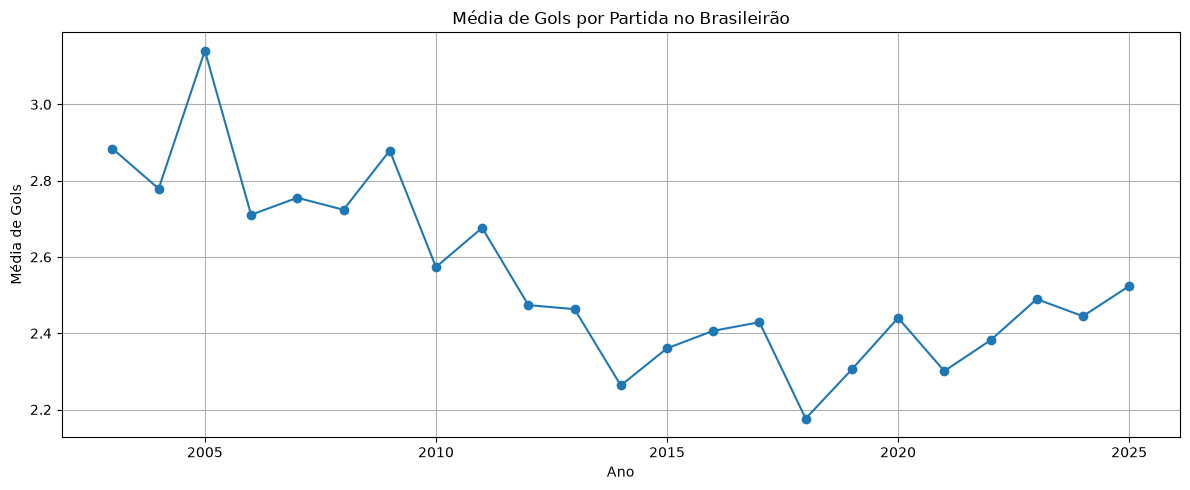

In [86]:
media_por_ano.plot(kind = "line", figsize = (12, 5), marker = "o")

plt.title("Média de Gols por Partida no Brasileirão")
plt.xlabel("Ano")
plt.ylabel("Média de Gols")
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretação:**

A média de gols apresentou variações significativas ao longo das temporadas. No início do período, os jogos tinham médias relativamente elevadas, com destaque para 2005, quando foram registrados aproximadamente 3,14 gols por partida. No entanto, posteriormente observa-se uma tendência geral de redução, atingindo o menor valor em 2018, com cerca de 2,18 gols.  

A partir de 2019, a média voltou a oscilar, apresentando recuperação em alguns anos. Em 2025, chegou a aproximadamente 2,52 gols por partida, valor próximo da média geral de 2,56.

### 1.2. Como Ocorreu a Distribuição Geral dos Resultados das Partidas?

In [87]:
def classificar_resultado(linha):
    if linha["mandante_Placar"] > linha["visitante_Placar"]:
        return "Vitória do Mandante"

    elif linha["mandante_Placar"] < linha["visitante_Placar"]:
        return "Vitória do Visitante"

    else:
        return "Empate"

df["resultado"] = df.apply(classificar_resultado, axis = 1)

contagem_resultados = df["resultado"].value_counts()
contagem_resultados

resultado
Vitória do Mandante     4550
Empate                  2421
Vitória do Visitante    2194
Name: count, dtype: int64

In [88]:
resultados_por_ano = pd.crosstab(df["ano"], df["resultado"], normalize = "index") * 100
resultados_por_ano.round(2)

resultado,Empate,Vitória do Mandante,Vitória do Visitante
ano,,,
2003,25.72,53.80,20.47
2004,25.36,52.17,22.46
2005,22.29,50.87,26.84
2006,25.53,50.26,24.21
2007,23.68,50.53,25.79
2008,25.26,54.74,20.00
2009,26.84,51.32,21.84
2010,31.05,47.11,21.84
2011,27.63,48.42,23.95


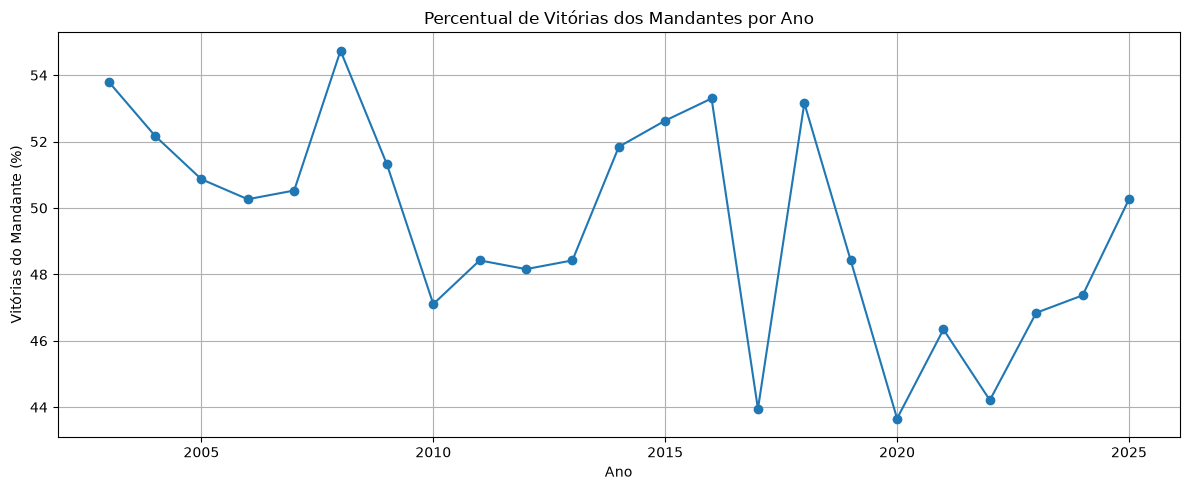

In [89]:
resultados_por_ano["Vitória do Mandante"].plot(kind = "line", figsize = (12, 5), marker = "o")

plt.title("Percentual de Vitórias dos Mandantes por Ano")
plt.xlabel("Ano")
plt.ylabel("Vitórias do Mandante (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretação:**

As vitórias dos mandantes foram o resultado mais frequente, representando aproximadamente metade das partidas analisadas. Os empates corresponderam a cerca de 1/4 dos jogos, enquanto as vitórias dos visitantes foram menos frequentes.

Isso sugere uma possível existência de vantagem associada a jogar em casa, visto que historicamente, os times mandantes venceram mais vezes do que os visitantes.

### 1.3. Como se Comportou o Percentual de Vitórias do Mandante por Temporada?

In [90]:
vitorias_mandante = resultados_por_ano["Vitória do Mandante"]

print("Maior percentual:")
print(vitorias_mandante.idxmax(), vitorias_mandante.max())

print("\nMenor Percentual:")
print(vitorias_mandante.idxmin(), vitorias_mandante.min())

Maior percentual:
2008 54.736842105263165

Menor Percentual:
2020 43.656716417910445


In [91]:
resultados_por_ano[
    [
        "Vitória do Mandante",
    ]
].round(2)

resultado,Vitória do Mandante
ano,
2003,53.80
2004,52.17
2005,50.87
2006,50.26
2007,50.53
2008,54.74
2009,51.32
2010,47.11
2011,48.42


**Interpretação:**

O percentual de vitórias dos mandantes apresentou consideráveis oscilações ao longo do período. Em 2008, aproximadamente 55% das partidas terminaram com vitória do time da casa, enquanto em 2020 esse percentual caiu para cerca de 44% - o menor valor registrado na série.

A queda observada em 2020 chama a atenção por coincidir com o período da pandemia de COVID-19, quando diversas partidas ocorreram sem público nos estádios.

Esse resultado levanta a possível hipótese de que a ausência de torcedores possa ter contribuído para a redução da vantagem de jogar em casa. Entretanto, vale salientar que a coincidência temporal não comprova uma relação de causa e efeito.

### 1.4. Como os Resultados Antes, Durante e Depois da Pandemia se Distribuíram?

In [92]:
def classificar_periodo(ano):
    if ano <= 2019:
        return "Pré-pandemia"

    elif ano <= 2021:
        return "Período de Pandemia"

    else:
        return "Pós-pandemia"

df["periodo"] = df["ano"].apply(classificar_periodo)

In [93]:
df_recorte = df[df["ano"].between(2017, 2023)].copy()

comparacao_recorte = pd.crosstab(df_recorte["periodo"], df_recorte["resultado"], normalize = "index") * 100
comparacao_recorte.round(2)

resultado,Empate,Vitória do Mandante,Vitória do Visitante
periodo,,,
Período de Pandemia,29.08,45.39,25.53
Pré-pandemia,27.28,48.51,24.21
Pós-pandemia,27.11,45.53,27.37


**Interpretação:**

* **Pré-pandemia:** as vitórias dos mandantes representaram 48,51% das partidas, enquanto os empates corresponderam a 27,28% e as vitórias dos visitantes a 24,21%.

* **Durante a pandemia:** o percentual de vitórias dos mandantes caiu para 45,39%, enquanto os empates aumentaram para 29,08%, o maior percentual entre os três períodos. As vitórias dos visitantes também aumentaram, chegando a 25,53%.

* **Pós-pandemia:** as vitórias dos mandantes permaneceram em um patamar próximo ao observado durante a pandemia, com 45,53%. Já as vitórias dos visitantes aumentaram para 27,37%, o maior percentual entre os três períodos.

Os resultados indicam uma redução da participação das vitórias dos mandantes em comparação com o período pré-pandemia. Ademais, no recorte pós-pandemia, as vitórias dos visitantes passaram a representar uma parcela maior dos resultados em relação aos períodos anteriores.

Porém, como a comparação utiliza apenas duas a três temporadas por período, não é possível atribuir essas mudanças exclusivamente à pandemia.

## 2. Desempenho Ofensivo e Defensivo das Equipes

### Objetivo

Identificar as equipes com maior produção ofensiva, melhor desempenho defensivo e maior saldo de gols no período analisado.

Para isso, serão utilizados os placares das partidas, considerando os gols marcados e sofridos por cada equipe. Além dos totais históricos, serão calculadas médias por partida para reduzir o efeito das diferenças na quantidade de jogos disputados.

In [94]:
mandantes = {
    "equipe": df["mandante"],
    "gols_marcados": df["mandante_Placar"],
    "gols_sofridos": df["visitante_Placar"]
}

df_mandantes = pd.DataFrame(mandantes)
df_mandantes

,equipe,gols_marcados,gols_sofridos
0,Guarani,4,2
1,Athletico-PR,2,0
2,Flamengo,1,1
3,Goias,2,2
4,Internacional,1,1
...,...,...,...
9160,Santos,3,0
9161,Sport,0,4
9162,Botafogo-RJ,4,2
9163,Atletico-MG,5,0


In [95]:
visitantes = {
    "equipe": df["visitante"],
    "gols_marcados": df["visitante_Placar"],
    "gols_sofridos": df["mandante_Placar"]
}

df_visitantes = pd.DataFrame(visitantes)
df_visitantes

,equipe,gols_marcados,gols_sofridos
0,Vasco,2,4
1,Gremio,0,2
2,Coritiba,1,1
3,Paysandu,2,2
4,Ponte Preta,1,1
...,...,...,...
9160,Cruzeiro,0,3
9161,Gremio,4,0
9162,Fortaleza,2,4
9163,Vasco,0,5


In [96]:
df_equipes = pd.concat([df_mandantes, df_visitantes], ignore_index = True)
df_equipes.head()

,equipe,gols_marcados,gols_sofridos
0,Guarani,4,2
1,Athletico-PR,2,0
2,Flamengo,1,1
3,Goias,2,2
4,Internacional,1,1


In [97]:
df_equipes.shape

(18330, 3)

In [98]:
gols_marcados_equipes = df_equipes.groupby("equipe")["gols_marcados"].sum()
gols_marcados_equipes

equipe
America-MG          227
America-RN           24
Athletico-PR       1072
Atletico-GO         317
Atletico-MG        1221
Avai                274
Bahia               579
Barueri              59
Botafogo-RJ         993
Bragantino          292
Brasiliense          49
CSA                  24
Ceara               311
Chapecoense         261
Corinthians        1095
Coritiba            693
Criciuma            236
Cruzeiro           1111
Cuiaba              134
Figueirense         530
Flamengo           1308
Fluminense         1181
Fortaleza           470
Goias               789
Gremio             1110
Gremio Prudente      39
Guarani             140
Internacional      1138
Ipatinga             37
Joinville            26
Juventude           416
Mirassol             63
Nautico             224
Palmeiras          1203
Parana              312
Paysandu            193
Ponte Preta         414
Portuguesa          137
Santa Cruz           86
Santo Andre          46
Santos             1223
Sao Caeta

In [99]:
gols_sofridos_equipes = df_equipes.groupby("equipe")["gols_sofridos"].sum()
gols_sofridos_equipes

equipe
America-MG          332
America-RN           80
Athletico-PR       1011
Atletico-GO         421
Atletico-MG        1076
Avai                415
Bahia               660
Barueri              52
Botafogo-RJ         948
Bragantino          285
Brasiliense          68
CSA                  58
Ceara               357
Chapecoense         359
Corinthians         924
Coritiba            787
Criciuma            325
Cruzeiro            922
Cuiaba              167
Figueirense         622
Flamengo           1031
Fluminense         1110
Fortaleza           518
Goias               839
Gremio              934
Gremio Prudente      64
Guarani             180
Internacional       945
Ipatinga             67
Joinville            48
Juventude           568
Mirassol             39
Nautico             318
Palmeiras           906
Parana              369
Paysandu            245
Ponte Preta         534
Portuguesa          157
Santa Cruz          145
Santo Andre          61
Santos             1032
Sao Caeta

### 2.1. Quais Equipes Marcaram mais Gols?

In [100]:
gols_marcados_equipes.sort_values(ascending=False).head(15)

equipe
Flamengo         1308
Sao Paulo        1259
Santos           1223
Atletico-MG      1221
Palmeiras        1203
Fluminense       1181
Internacional    1138
Cruzeiro         1111
Gremio           1110
Corinthians      1095
Athletico-PR     1072
Botafogo-RJ       993
Vasco             886
Goias             789
Coritiba          693
Name: gols_marcados, dtype: int64

### 2.2. Quais Equipes Sofreram Menos Gols?

In [101]:
gols_sofridos_equipes.sort_values(ascending=True).head(15)

equipe
Mirassol            39
Joinville           48
Barueri             52
CSA                 58
Santo Andre         61
Gremio Prudente     64
Ipatinga            67
Brasiliense         68
America-RN          80
Santa Cruz         145
Portuguesa         157
Cuiaba             167
Guarani            180
Sao Caetano        199
Paysandu           245
Name: gols_sofridos, dtype: int64

### 2.3. Quais Equipes Tiveram o Maior Saldo de Gols?

In [102]:
saldo_gols_equipes = gols_marcados_equipes - gols_sofridos_equipes
saldo_gols_equipes.sort_values(ascending=False).head(15)

equipe
Palmeiras        297
Sao Paulo        290
Flamengo         277
Internacional    193
Santos           191
Cruzeiro         189
Gremio           176
Corinthians      171
Atletico-MG      145
Fluminense        71
Athletico-PR      61
Botafogo-RJ       45
Mirassol          24
Sao Caetano       10
Barueri            7
dtype: int64

In [103]:
totais_equipes = df_equipes.groupby("equipe").agg(gols_marcados = ("gols_marcados", "sum"), gols_sofridos = ("gols_sofridos", "sum"))
totais_equipes["saldo_gols"] = totais_equipes["gols_marcados"] - totais_equipes["gols_sofridos"]
totais_equipes.head(10)

,gols_marcados,gols_sofridos,saldo_gols
equipe,,,
America-MG,227,332,-105
America-RN,24,80,-56
Athletico-PR,1072,1011,61
Atletico-GO,317,421,-104
Atletico-MG,1221,1076,145
Avai,274,415,-141
Bahia,579,660,-81
Barueri,59,52,7
Botafogo-RJ,993,948,45


In [104]:
partidas_equipes = df_equipes.groupby("equipe").size()
partidas_equipes

equipe
America-MG         228
America-RN          38
Athletico-PR       818
Atletico-GO        304
Atletico-MG        855
Avai               266
Bahia              502
Barueri             38
Botafogo-RJ        772
Bragantino         228
Brasiliense         42
CSA                 38
Ceara              304
Chapecoense        265
Corinthians        856
Coritiba           590
Criciuma           206
Cruzeiro           780
Cuiaba             152
Figueirense        438
Flamengo           894
Fluminense         894
Fortaleza          392
Goias              590
Gremio             814
Gremio Prudente     38
Guarani            130
Internacional      856
Ipatinga            38
Joinville           38
Juventude          362
Mirassol            38
Nautico            190
Palmeiras          810
Parana             248
Paysandu           134
Ponte Preta        362
Portuguesa         114
Santa Cruz          76
Santo Andre         38
Santos             856
Sao Caetano        172
Sao Paulo          894
Spor

In [105]:
totais_equipes["media_gols_marcados"] = (totais_equipes["gols_marcados"] / partidas_equipes)
totais_equipes["media_gols_marcados"].head(10)


equipe
America-MG      0.995614
America-RN      0.631579
Athletico-PR    1.310513
Atletico-GO     1.042763
Atletico-MG     1.428070
Avai            1.030075
Bahia           1.153386
Barueri         1.552632
Botafogo-RJ     1.286269
Bragantino      1.280702
Name: media_gols_marcados, dtype: float64

In [106]:
totais_equipes["media_gols_marcados"].sort_values(ascending=False).head(10)

equipe
Mirassol       1.657895
Barueri        1.552632
Palmeiras      1.485185
Flamengo       1.463087
Paysandu       1.440299
Santos         1.428738
Atletico-MG    1.428070
Cruzeiro       1.424359
Sao Paulo      1.408277
Gremio         1.363636
Name: media_gols_marcados, dtype: float64

In [107]:
totais_equipes["media_gols_sofridos"] = (totais_equipes["gols_sofridos"] / partidas_equipes)
totais_equipes["media_gols_sofridos"].head(10)

equipe
America-MG      1.456140
America-RN      2.105263
Athletico-PR    1.235941
Atletico-GO     1.384868
Atletico-MG     1.258480
Avai            1.560150
Bahia           1.314741
Barueri         1.368421
Botafogo-RJ     1.227979
Bragantino      1.250000
Name: media_gols_sofridos, dtype: float64

In [108]:
totais_equipes["media_gols_sofridos"].sort_values(ascending=True).head(10)

equipe
Mirassol         1.026316
Corinthians      1.079439
Sao Paulo        1.083893
Cuiaba           1.098684
Internacional    1.103972
Palmeiras        1.118519
Gremio           1.147420
Flamengo         1.153244
Sao Caetano      1.156977
Ceara            1.174342
Name: media_gols_sofridos, dtype: float64

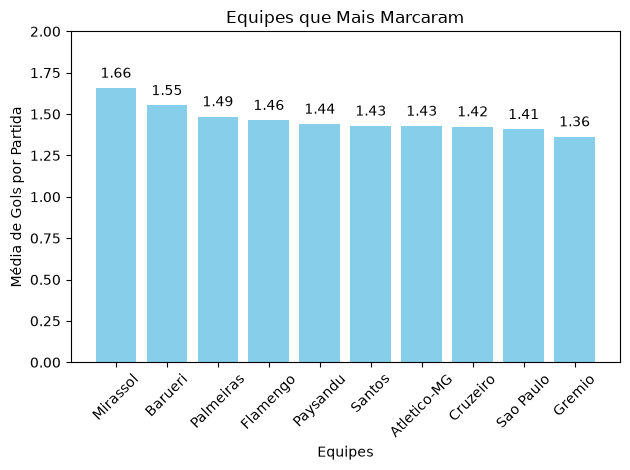

In [109]:
categorias = totais_equipes.sort_values(by="media_gols_marcados", ascending=False).head(10).index
valores = totais_equipes.sort_values(by="media_gols_marcados", ascending=False).head(10)["media_gols_marcados"]

barras = plt.bar(categorias, valores, color='skyblue')
plt.bar_label(barras, fmt='%.2f', padding=5)
plt.ylim(0, 2)

plt.xlabel('Equipes')
plt.ylabel('Média de Gols por Partida')
plt.title('Equipes que Mais Marcaram')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

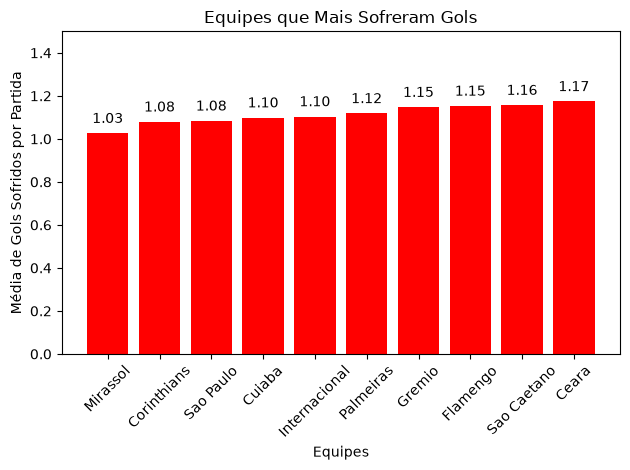

In [110]:
categorias = totais_equipes.sort_values(by="media_gols_sofridos", ascending=True).head(10).index
valores = totais_equipes.sort_values(by="media_gols_sofridos", ascending=True).head(10)["media_gols_sofridos"]

barras = plt.bar(categorias, valores, color='red')
plt.bar_label(barras, fmt='%.2f', padding=5)
plt.ylim(0, 1.5)

plt.xlabel('Equipes')
plt.ylabel('Média de Gols Sofridos por Partida')
plt.title('Equipes que Mais Sofreram Gols')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [111]:
totais_equipes["saldo_medio_gols"] = totais_equipes["media_gols_marcados"] - totais_equipes["media_gols_sofridos"]
totais_equipes["saldo_medio_gols"].sort_values(ascending=False).head(10)

equipe
Mirassol         0.631579
Palmeiras        0.366667
Sao Paulo        0.324385
Flamengo         0.309843
Cruzeiro         0.242308
Internacional    0.225467
Santos           0.223131
Gremio           0.216216
Corinthians      0.199766
Barueri          0.184211
Name: saldo_medio_gols, dtype: float64

In [112]:
totais_equipes.sort_values(by="saldo_medio_gols", ascending=False).head(10)[["media_gols_marcados", "media_gols_sofridos", "saldo_medio_gols"]]

,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,
Mirassol,1.657895,1.026316,0.631579
Palmeiras,1.485185,1.118519,0.366667
Sao Paulo,1.408277,1.083893,0.324385
Flamengo,1.463087,1.153244,0.309843
Cruzeiro,1.424359,1.182051,0.242308
Internacional,1.329439,1.103972,0.225467
Santos,1.428738,1.205607,0.223131
Gremio,1.363636,1.147420,0.216216
Corinthians,1.279206,1.079439,0.199766


## Análise do Saldo Médio de Gols por Equipe

**1. Qual equipe ficou em primeiro lugar no saldo médio de gols?**

O **Mirassol** ficou em primeiro lugar, com saldo médio de aproximadamente **+0,63 gol por partida**. A equipe marcou, em média, 1,66 gol e sofreu 1,03 gol por partida.

**2. Ela se destaca mais por marcar muitos gols, sofrer poucos gols ou pelos dois fatores?**

O Mirassol se destaca pelos dois fatores. Sua média de 1,66 gol marcado por partida foi a maior entre as equipes analisadas, enquanto sua média de 1,03 gol sofrido por partida foi a menor. Essa combinação contribuiu para o melhor saldo médio de gols do levantamento.

**3. Por que usar médias por partida pode ser mais justo do que comparar apenas os totais históricos?**

As equipes disputaram quantidades diferentes de partidas no período analisado. Comparar apenas os totais de gols pode favorecer equipes que participaram de mais jogos. As médias por partida permitem comparar o desempenho ofensivo e defensivo levando em consideração o número de jogos disputados, tornando a análise mais equilibrada.

**Observação:**
O Mirassol disputou 38 partidas no conjunto de dados analisado, enquanto equipes como Palmeiras, Flamengo e São Paulo disputaram centenas de jogos. Portanto, embora o Mirassol lidere as médias calculadas, essa comparação considera períodos e quantidades de partidas distintas.


## 3. Refinando Rankings

### Objetivo

Filtragem de equipes com pelo menos 100 partidas no período analisado e refazer os rankings ofensivo e defensivo, reduzindo o efeito de equipes com poucas participações durante o campeonato.

In [113]:
equipes_filtradas = totais_equipes.loc[partidas_equipes >= 100]
equipes_filtradas.head(15)

,gols_marcados,gols_sofridos,saldo_gols,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,,,,
America-MG,227,332,-105,0.995614,1.456140,-0.460526
Athletico-PR,1072,1011,61,1.310513,1.235941,0.074572
Atletico-GO,317,421,-104,1.042763,1.384868,-0.342105
Atletico-MG,1221,1076,145,1.428070,1.258480,0.169591
Avai,274,415,-141,1.030075,1.560150,-0.530075
Bahia,579,660,-81,1.153386,1.314741,-0.161355
Botafogo-RJ,993,948,45,1.286269,1.227979,0.058290
Bragantino,292,285,7,1.280702,1.250000,0.030702
Ceara,311,357,-46,1.023026,1.174342,-0.151316


In [114]:
equipes_filtradas.sort_values(by='saldo_medio_gols', ascending=False).head(10)

,gols_marcados,gols_sofridos,saldo_gols,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,,,,
Palmeiras,1203,906,297,1.485185,1.118519,0.366667
Sao Paulo,1259,969,290,1.408277,1.083893,0.324385
Flamengo,1308,1031,277,1.463087,1.153244,0.309843
Cruzeiro,1111,922,189,1.424359,1.182051,0.242308
Internacional,1138,945,193,1.329439,1.103972,0.225467
Santos,1223,1032,191,1.428738,1.205607,0.223131
Gremio,1110,934,176,1.363636,1.147420,0.216216
Corinthians,1095,924,171,1.279206,1.079439,0.199766
Atletico-MG,1221,1076,145,1.428070,1.258480,0.169591


In [115]:
equipes_filtradas.sort_values(by='media_gols_marcados', ascending=False).head(10)

,gols_marcados,gols_sofridos,saldo_gols,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,,,,
Palmeiras,1203,906,297,1.485185,1.118519,0.366667
Flamengo,1308,1031,277,1.463087,1.153244,0.309843
Paysandu,193,245,-52,1.440299,1.828358,-0.388060
Santos,1223,1032,191,1.428738,1.205607,0.223131
Atletico-MG,1221,1076,145,1.428070,1.258480,0.169591
Cruzeiro,1111,922,189,1.424359,1.182051,0.242308
Sao Paulo,1259,969,290,1.408277,1.083893,0.324385
Gremio,1110,934,176,1.363636,1.147420,0.216216
Goias,789,839,-50,1.337288,1.422034,-0.084746


In [116]:
equipes_filtradas.sort_values(by='media_gols_sofridos', ascending=True).head(10)

,gols_marcados,gols_sofridos,saldo_gols,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,,,,
Corinthians,1095,924,171,1.279206,1.079439,0.199766
Sao Paulo,1259,969,290,1.408277,1.083893,0.324385
Cuiaba,134,167,-33,0.881579,1.098684,-0.217105
Internacional,1138,945,193,1.329439,1.103972,0.225467
Palmeiras,1203,906,297,1.485185,1.118519,0.366667
Gremio,1110,934,176,1.363636,1.147420,0.216216
Flamengo,1308,1031,277,1.463087,1.153244,0.309843
Sao Caetano,209,199,10,1.215116,1.156977,0.058140
Ceara,311,357,-46,1.023026,1.174342,-0.151316


In [117]:
equipes_filtradas.sort_values(by="saldo_medio_gols", ascending=False).head(10)[["media_gols_marcados", "media_gols_sofridos", "saldo_medio_gols"]]

,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,
Palmeiras,1.485185,1.118519,0.366667
Sao Paulo,1.408277,1.083893,0.324385
Flamengo,1.463087,1.153244,0.309843
Cruzeiro,1.424359,1.182051,0.242308
Internacional,1.329439,1.103972,0.225467
Santos,1.428738,1.205607,0.223131
Gremio,1.363636,1.147420,0.216216
Corinthians,1.279206,1.079439,0.199766
Atletico-MG,1.428070,1.258480,0.169591


### Análise do Desempenho das Equipes após Filtragem

Após filtrar as equipes que disputaram ao menos 100 partidas, o Palmeiras apresentou o maior saldo médio de gols entre as dez primeiras colocadas, com aproximadamente +0,37 gol por partida. O resultado é consequência da combinação entre uma média ofensiva de 1,49 gol marcado e uma média defensiva de 1,12 gol sofrido por jogo.

O Corinthians se destacou defensivamente, apresentando a menor média de gols sofridos entre as equipes da tabela, com aproximadamente 1,08 por partida. A análise também demonstra a importância de considerar a quantidade de jogos disputados: o filtro reduz a influência de equipes com poucas partidas e torna a comparação mais consistente dentro do recorte escolhido. Entretanto, o limite de 100 jogos é uma escolha metodológica, e não elimina todas as diferenças entre os períodos e as participações dos clubes.

## 4. Análise das Estatísticas das Partidas

In [118]:
df_estatisticas = pd.read_csv("../data/raw/campeonato-brasileiro-estatisticas-full.csv")
df_estatisticas.shape

(18330, 13)

In [119]:
df_estatisticas.columns

Index(['partida_id', 'rodata', 'clube', 'chutes', 'chutes_no_alvo',
       'posse_de_bola', 'passes', 'precisao_passes', 'faltas',
       'cartao_amarelo', 'cartao_vermelho', 'impedimentos', 'escanteios'],
      dtype='str')

In [120]:
df_estatisticas.head(15)

,partida_id,rodata,clube,chutes,chutes_no_alvo,posse_de_bola,passes,precisao_passes,faltas,cartao_amarelo,cartao_vermelho,impedimentos,escanteios
0,1,1,Vasco,0,0,NaN,0,NaN,0,0,0,0,0
1,1,1,Guarani,0,0,NaN,0,NaN,0,0,0,0,0
2,2,1,Athletico-PR,0,0,NaN,0,NaN,0,0,0,0,0
3,2,1,Gremio,0,0,NaN,0,NaN,0,0,0,0,0
4,3,1,Flamengo,0,0,NaN,0,NaN,0,0,0,0,0
5,3,1,Coritiba,0,0,NaN,0,NaN,0,0,0,0,0
6,4,1,Goias,0,0,NaN,0,NaN,0,0,0,0,0
7,4,1,Paysandu,0,0,NaN,0,NaN,0,0,0,0,0
8,5,1,Internacional,0,0,NaN,0,NaN,0,0,0,0,0
9,5,1,Ponte Preta,0,0,NaN,0,NaN,0,0,0,0,0


In [121]:
df_estatisticas.isnull().sum()

partida_id             0
rodata                 0
clube                  0
chutes                 0
chutes_no_alvo         0
posse_de_bola      10762
passes                 0
precisao_passes    13066
faltas                 0
cartao_amarelo         0
cartao_vermelho        0
impedimentos           0
escanteios             0
dtype: int64

In [122]:
df_estatisticas.describe()

,partida_id,rodata,chutes,chutes_no_alvo,passes,faltas,cartao_amarelo,cartao_vermelho,impedimentos,escanteios
count,18330.000000,18330.000000,18330.000000,18330.000000,18330.000000,18330.000000,18330.000000,18330.000000,18330.000000,18330.000000
mean,4583.000000,20.080742,5.287998,1.424659,172.426077,6.109602,0.963284,0.052755,0.671304,2.155810
std,2645.779765,11.406726,7.078235,2.426625,215.636407,7.818816,1.475430,0.244307,1.245661,3.200461
min,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2292.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4583.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6874.000000,30.000000,11.000000,3.000000,385.000000,13.000000,2.000000,0.000000,1.000000,4.000000
max,9165.000000,46.000000,37.000000,18.000000,848.000000,34.000000,10.000000,3.000000,10.000000,23.000000


In [123]:
colunas_estatisticas = [
    "chutes",
    "chutes_no_alvo",
    "passes",
    "faltas",
    "escanteios"
]

(df_estatisticas[colunas_estatisticas] == 0).all(axis=1).sum()

np.int64(10750)

In [124]:
df_estatisticas["estatisticas_zeradas"] = (df_estatisticas[colunas_estatisticas] == 0).all(axis=1)
df_estatisticas["estatisticas_zeradas"].value_counts()

estatisticas_zeradas
True     10750
False     7580
Name: count, dtype: int64

In [125]:
df[["ID", "data", "ano"]].head(10)

,ID,data,ano
0,1,2003-03-29,2003
1,2,2003-03-29,2003
2,3,2003-03-30,2003
3,4,2003-03-30,2003
4,5,2003-03-30,2003
5,6,2003-03-30,2003
6,7,2003-03-30,2003
7,8,2003-03-30,2003
8,9,2003-03-30,2003
9,10,2003-03-30,2003


In [126]:
df_anos = df[["ID", "ano"]].rename(columns={"ID": "partida_id"})
df_estatisticas = df_estatisticas.merge(df_anos, on="partida_id", how="left", validate="many_to_one")

In [127]:
df_estatisticas.groupby("ano")["estatisticas_zeradas"].sum().sort_values(ascending=False).head(20)

ano
2003    1104
2004    1104
2005     924
2006     760
2007     760
2008     760
2009     760
2010     760
2011     760
2012     760
2013     760
2024     760
2014     728
2019      46
2017       2
2020       2
2015       0
2016       0
2018       0
2021       0
Name: estatisticas_zeradas, dtype: int64

In [128]:
resumo_zerados = df_estatisticas.groupby("ano").agg(total_registros = ("estatisticas_zeradas", "size"), registros_zerados = ("estatisticas_zeradas", "sum"))
resumo_zerados["percentual_zerados"] = (resumo_zerados["registros_zerados"] / resumo_zerados["total_registros"] * 100)

resumo_zerados.sort_values(by="percentual_zerados", ascending=False).round(2)

,total_registros,registros_zerados,percentual_zerados
ano,,,
2003,1104,1104,100.00
2004,1104,1104,100.00
2005,924,924,100.00
2006,760,760,100.00
2007,760,760,100.00
2008,760,760,100.00
2009,760,760,100.00
2010,760,760,100.00
2011,760,760,100.00


In [129]:
resumo_chutes = df_estatisticas.groupby("ano").agg(
    total_registros = ("chutes", "count"), 
    chutes_positivos = ("chutes", lambda serie: (serie > 0).sum()),
    chutes_no_alvo_positivos = ("chutes_no_alvo", lambda serie: (serie > 0).sum())
    )

resumo_chutes

,total_registros,chutes_positivos,chutes_no_alvo_positivos
ano,,,
2003,1104,0,0
2004,1104,0,0
2005,924,0,0
2006,760,0,0
2007,760,0,0
2008,760,0,0
2009,760,0,0
2010,760,0,0
2011,760,0,0


In [130]:
anos_validos = list(range(2015, 2024)) + [2025]

df_chutes = df_estatisticas.loc[df_estatisticas["ano"].isin(anos_validos)]

df_chutes[["chutes", "chutes_no_alvo"]].describe()

,chutes,chutes_no_alvo
count,7598.000000,7598.000000
mean,12.705712,3.436957
std,5.118344,2.699980
min,0.000000,0.000000
25%,9.000000,1.000000
50%,12.000000,3.000000
75%,16.000000,5.000000
max,37.000000,18.000000


In [131]:
resultados_mandante = pd.DataFrame({
    "partida_id": df["ID"],
    "clube": df["mandante"],
    "gols_marcados": df["mandante_Placar"],
    "gols_sofridos": df["visitante_Placar"]
})

resultados_visitante = pd.DataFrame({
    "partida_id": df["ID"],
    "clube": df["visitante"],
    "gols_marcados": df["visitante_Placar"],
    "gols_sofridos": df["mandante_Placar"]
})

df_resultados_equipes = pd.concat([resultados_mandante, resultados_visitante], ignore_index=True)

In [132]:
df_resultados_equipes["resultado"] = "Empate"

df_resultados_equipes.loc[df_resultados_equipes["gols_marcados"] > df_resultados_equipes["gols_sofridos"], "resultado"] = "Vitória"
df_resultados_equipes.loc[df_resultados_equipes["gols_marcados"] < df_resultados_equipes["gols_sofridos"], "resultado"] = "Derrota"

In [133]:
df_resultados_equipes["resultado"].value_counts()

resultado
Vitória    6744
Derrota    6744
Empate     4842
Name: count, dtype: int64

In [134]:
df_analise = df_chutes.merge(df_resultados_equipes[["partida_id", "clube", "resultado"]], on=["partida_id", "clube"], how="inner")

In [135]:
df_analise["resultado"].value_counts()

resultado
Derrota    2777
Vitória    2777
Empate     2044
Name: count, dtype: int64

**Nota de qualidade:** esta comparação inicial utiliza o recorte exploratório original e deve ser considerada preliminar. A auditoria apresentada na seção 5 identificará limitações em determinados anos. Para a comparação final, utilize a amostra filtrada da seção 6, que documenta as exclusões.

### Equipes que Finalizam Mais no Gol Tendem a Vencer Mais Partidas?

In [136]:
media_resultados = df_analise.groupby("resultado").agg(media_chutes = ("chutes", "mean"), media_chutes_no_alvo = ("chutes_no_alvo", "mean"))
media_resultados.round(2)

,media_chutes,media_chutes_no_alvo
resultado,,
Derrota,12.03,2.79
Empate,12.74,3.24
Vitória,13.36,4.23


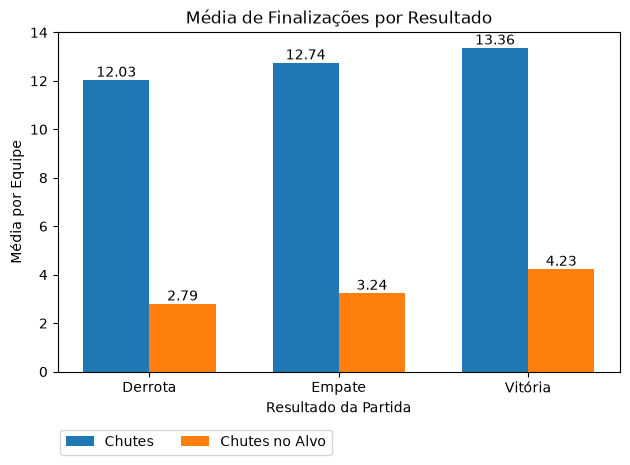

In [137]:
import numpy as np

resultados = ["Derrota", "Empate", "Vitória"]

valores_chutes = media_resultados.loc[resultados, "media_chutes"]
valores_alvo = media_resultados.loc[resultados, "media_chutes_no_alvo"]

posicoes = np.arange(len(resultados))
largura = 0.35

barras1 = plt.bar(posicoes - largura/2, valores_chutes, largura, label = "Chutes")
barras2 = plt.bar(posicoes + largura/2, valores_alvo, largura, label = "Chutes no Alvo")

plt.bar_label(barras1, fmt="%.2f", padding=0.1)
plt.bar_label(barras2, fmt="%.2f", padding=0.1)

plt.xticks(posicoes, resultados)
plt.xlabel("Resultado da Partida")
plt.ylabel("Média por Equipe")
plt.title("Média de Finalizações por Resultado")
plt.legend(loc = "upper right", bbox_to_anchor = (0.5, -0.15), ncol = 2)
plt.tight_layout()
plt.show()

In [138]:
media_resultados["precisao_chutes"] = (
    media_resultados["media_chutes_no_alvo"]/media_resultados["media_chutes"]
) * 100

In [139]:
media_resultados.round(2)

,media_chutes,media_chutes_no_alvo,precisao_chutes
resultado,,,
Derrota,12.03,2.79,23.23
Empate,12.74,3.24,25.40
Vitória,13.36,4.23,31.65


### Leitura Preliminar

Na amostra exploratória inicial, as equipes vencedoras apresentaram maiores médias de finalizações e de chutes no alvo. Entretanto, essa comparação inclui temporadas e partidas com sinais de problemas de qualidade nos registros de finalização.

Portanto, os valores desta etapa não devem ser tratados como conclusão definitiva. A auditoria da seção 5 e a análise com amostra tratada da seção 6 são necessárias antes de consolidar a interpretação.

## 5. Auditoria da Qualidade das Estatísticas de Finalização

### Objetivo

Antes de interpretar a relação entre finalizações e resultados, é necessário avaliar a consistência dos registros. Valores iguais a zero podem representar uma ocorrência real, mas também podem indicar ausência de coleta ou preenchimento.

Nesta etapa, os zeros serão tratados como **sinais para investigação**, e não automaticamente como erros.

### 5.1. Proporção Anual de Registros Sem Chutes no Alvo

A tabela e o gráfico abaixo mostram quantos registros de equipes apresentam zero chutes no alvo em cada temporada. A proporção, isoladamente, não permite afirmar que os valores estejam incorretos; ela ajuda a identificar anos que merecem inspeção.

In [140]:
resumo_zerados = df_chutes.groupby("ano").agg(
    total_registros=("chutes_no_alvo", "size"),
    registros_zerados=("chutes_no_alvo", lambda serie: (serie == 0).sum()),
    registros_positivos=("chutes_no_alvo", lambda serie: (serie > 0).sum())
)

resumo_zerados["percentual_zerados"] = (
    resumo_zerados["registros_zerados"]
    / resumo_zerados["total_registros"]
) * 100

resumo_zerados.round(2)

,total_registros,registros_zerados,registros_positivos,percentual_zerados
ano,,,,
2015,760,720,40,94.74
2016,758,728,30,96.04
2017,760,20,740,2.63
2018,760,17,743,2.24
2019,760,59,701,7.76
2020,536,13,523,2.43
2021,984,27,957,2.74
2022,760,12,748,1.58
2023,760,13,747,1.71


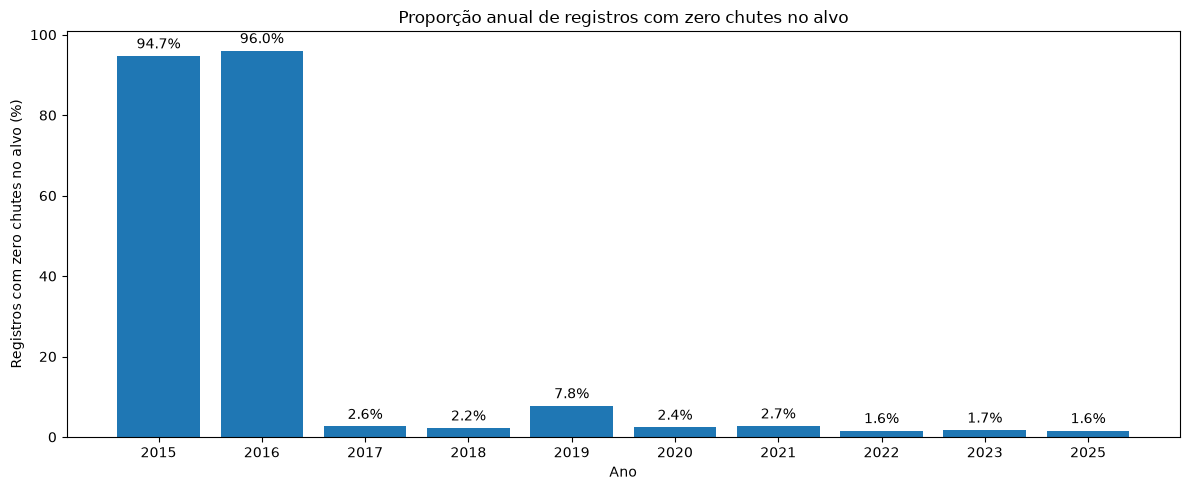

In [141]:
plt.figure(figsize=(12, 5))

barras = plt.bar(
    resumo_zerados.index.astype(str),
    resumo_zerados["percentual_zerados"]
)

plt.bar_label(barras, fmt="%.1f%%", padding=3)
plt.xlabel("Ano")
plt.ylabel("Registros com zero chutes no alvo (%)")
plt.title("Proporção anual de registros com zero chutes no alvo")
plt.tight_layout()
plt.show()

**Leitura Inicial:** os anos de 2015 e 2016 merecem atenção especial. Nos dados examinados, 720 de 760 registros de 2015 (94,74%) e 728 de 758 registros de 2016 (96,04%) apresentam zero chutes no alvo. Como há registros com chutes totais positivos e zero chutes no alvo em grande parte dessas observações, esses anos não devem ser misturados automaticamente às análises de precisão.

A decisão de excluir ou manter um período deve ser documentada e, idealmente, confrontada com a documentação da fonte original.

### 5.2. Inspeção dos Registros de 2015 e 2016

Vamos separar os registros com chutes totais positivos e nenhum chute no alvo. Isso permite observar se os zeros aparecem mesmo quando há finalizações registradas.

In [142]:
suspeitos_2015_2016 = df_chutes.loc[
    (df_chutes["ano"].isin([2015, 2016]))
    & (df_chutes["chutes"] > 0)
    & (df_chutes["chutes_no_alvo"] == 0),
    ["ano", "partida_id", "clube", "chutes", "chutes_no_alvo"]
]

print("Quantidade de registros:", len(suspeitos_2015_2016))
suspeitos_2015_2016.head(20)

Quantidade de registros: 1448


,ano,partida_id,clube,chutes,chutes_no_alvo
9972,2015,4987,Coritiba,16,0
9973,2015,4987,Chapecoense,13,0
9974,2015,4988,Atletico-MG,10,0
9975,2015,4988,Palmeiras,17,0
9977,2015,4989,Joinville,3,0
9978,2015,4990,Ponte Preta,17,0
9979,2015,4990,Gremio,11,0
9980,2015,4993,Cruzeiro,13,0
9981,2015,4993,Corinthians,11,0
9982,2015,4994,Figueirense,7,0


### 5.3. Investigação dos Zeros em 2019

Em 2019, o Athletico-PR apresentou 20 registros com zero chutes no alvo em 38 partidas. A investigação por partida mostrou que, nas mesmas 20 partidas, o adversário também aparece com zero chutes totais e zero chutes no alvo.

Esse padrão simultâneo é um indício mais forte de possível ausência de coleta ou preenchimento para essas partidas. Ainda assim, sem documentação da fonte, a análise não deve afirmar categoricamente a causa.

In [143]:
df_2019 = df_chutes.loc[df_chutes["ano"] == 2019].copy()

athletico_zerados = df_2019.loc[
    (df_2019["clube"] == "Athletico-PR")
    & (df_2019["chutes_no_alvo"] == 0)
].copy()

partidas_athletico = athletico_zerados["partida_id"].unique()

adversarios = df_2019.loc[
    (df_2019["partida_id"].isin(partidas_athletico))
    & (df_2019["clube"] != "Athletico-PR"),
    ["partida_id", "clube", "chutes", "chutes_no_alvo"]
].copy()

print("Registros zerados do Athletico-PR:", len(athletico_zerados))
print("Registros dos adversários nas mesmas partidas:", len(adversarios))
print(
    "Adversários com zero chutes totais:",
    (adversarios["chutes"] == 0).sum()
)
print(
    "Adversários com zero chutes no alvo:",
    (adversarios["chutes_no_alvo"] == 0).sum()
)

adversarios.sort_values("partida_id")

Registros zerados do Athletico-PR: 20
Registros dos adversários nas mesmas partidas: 20
Adversários com zero chutes totais: 20
Adversários com zero chutes no alvo: 20


,partida_id,clube,chutes,chutes_no_alvo
13179,6595,Goias,0,0
13211,6609,CSA,0,0
13228,6617,Cruzeiro,0,0
13309,6635,Sao Paulo,0,0
13289,6649,Atletico-MG,0,0
13312,6657,Gremio,0,0
13381,6690,Avai,0,0
13400,6703,Vasco,0,0
13431,6721,Chapecoense,0,0
13485,6743,Corinthians,0,0


In [144]:
partidas_zeradas_ambos = df_2019.groupby("partida_id").agg(
    equipes_registradas=("clube", "nunique"),
    soma_chutes=("chutes", "sum"),
    soma_chutes_no_alvo=("chutes_no_alvo", "sum")
)

partidas_zeradas_ambos = partidas_zeradas_ambos.loc[
    (partidas_zeradas_ambos["equipes_registradas"] == 2) & (partidas_zeradas_ambos["soma_chutes"] == 0) & (partidas_zeradas_ambos["soma_chutes_no_alvo"] == 0)
]

print("Partidas com as duas equipes zeradas:", len(partidas_zeradas_ambos))
partidas_zeradas_ambos

Partidas com as duas equipes zeradas: 23


,equipes_registradas,soma_chutes,soma_chutes_no_alvo
partida_id,,,
6517,2,0,0
6541,2,0,0
6595,2,0,0
6609,2,0,0
6617,2,0,0
6635,2,0,0
6649,2,0,0
6657,2,0,0
6690,2,0,0


**Interpretação:** nas partidas investigadas, o zero não está restrito ao Athletico-PR: os registros das duas equipes estão zerados. Isso recomenda sinalizar essas partidas como potencialmente incompletas. Também existem outros registros zerados em 2019; portanto, a inspeção de uma equipe não substitui uma auditoria de todos os jogos.

### 5.4. Verificação de Consistência entre Chutes Totais e Chutes no Alvo

Uma regra básica de consistência é que a quantidade de chutes no alvo não deve superar a quantidade de chutes totais. A verificação abaixo identifica violações dessa regra.

In [145]:
inconsistencias_chutes = df_chutes.loc[
    df_chutes["chutes_no_alvo"] > df_chutes["chutes"],
    ["ano", "partida_id", "clube", "chutes", "chutes_no_alvo"]
]

print("Registros em que chutes no alvo superam chutes totais:", len(inconsistencias_chutes))
inconsistencias_chutes.head(20)

Registros em que chutes no alvo superam chutes totais: 0


,ano,partida_id,clube,chutes,chutes_no_alvo


### 5.5. Decisões para a Análise Comparativa

Para reduzir o risco de conclusões distorcidas:

- 2015 e 2016 serão retirados da análise de chutes no alvo, pois apresentam proporções excepcionalmente elevadas de zeros.
- Em 2019, serão sinalizadas as partidas em que as duas equipes possuem zero chutes totais e zero chutes no alvo.
- Os demais zeros não serão removidos automaticamente: um zero isolado pode representar um resultado possível e precisa de evidência adicional para ser classificado como erro.
- A análise resultante representa uma amostra filtrada e deve ser descrita dessa forma.

## 6. Relação entre Finalizações e Resultado das Partidas

### Objetivo

Investigar se as equipes que vencem apresentam médias diferentes de chutes totais e chutes no alvo em comparação com equipes que empatam ou perdem.

A análise será feita com os registros após as decisões de qualidade descritas na seção anterior. Ela é observacional: diferenças entre grupos indicam associação, não causalidade.

### 6.1. Preparação da Amostra Analisada

Serão mantidos os anos a partir de 2017 que estão disponíveis na base, além de 2025. Os anos de 2015 e 2016 serão excluídos da análise de chutes no alvo. Em 2019, serão removidos apenas os registros das partidas em que as duas equipes aparecem com zero chutes totais e zero chutes no alvo.

In [146]:
anos_analise = list(range(2017, 2024)) + [2025]

df_chutes_analise = df_chutes.loc[
    df_chutes["ano"].isin(anos_analise)
].copy()

partidas_2019_suspeitas = (
    df_chutes_analise.loc[df_chutes_analise["ano"] == 2019]
    .groupby("partida_id")
    .agg(
        equipes=("clube", "nunique"),
        soma_chutes=("chutes", "sum"),
        soma_chutes_no_alvo=("chutes_no_alvo", "sum")
    )
)

partidas_2019_suspeitas = partidas_2019_suspeitas.loc[
    (partidas_2019_suspeitas["equipes"] == 2)
    & (partidas_2019_suspeitas["soma_chutes"] == 0)
    & (partidas_2019_suspeitas["soma_chutes_no_alvo"] == 0)
].index

quantidade_antes = len(df_chutes_analise)

df_chutes_analise = df_chutes_analise.loc[
    ~(
        (df_chutes_analise["ano"] == 2019)
        & (df_chutes_analise["partida_id"].isin(partidas_2019_suspeitas))
    )
].copy()

quantidade_depois = len(df_chutes_analise)

print("Registros antes da exclusão das partidas suspeitas:", quantidade_antes)
print("Partidas de 2019 sinalizadas:", len(partidas_2019_suspeitas))
print("Registros removidos:", quantidade_antes - quantidade_depois)
print("Registros na amostra final:", quantidade_depois)

Registros antes da exclusão das partidas suspeitas: 6080
Partidas de 2019 sinalizadas: 23
Registros removidos: 46
Registros na amostra final: 6034


### 6.2. Associação entre Resultado e Médias de Finalização

Para classificar o resultado do ponto de vista de cada equipe, cada partida gera duas observações: uma para o mandante e outra para o visitante.

In [147]:
resultados_mandante = pd.DataFrame({
    "partida_id": df["ID"],
    "clube": df["mandante"],
    "gols_marcados": df["mandante_Placar"],
    "gols_sofridos": df["visitante_Placar"]
})

resultados_visitante = pd.DataFrame({
    "partida_id": df["ID"],
    "clube": df["visitante"],
    "gols_marcados": df["visitante_Placar"],
    "gols_sofridos": df["mandante_Placar"]
})

df_resultados_equipes = pd.concat(
    [resultados_mandante, resultados_visitante],
    ignore_index=True
)

df_resultados_equipes["resultado"] = "Empate"

df_resultados_equipes.loc[
    df_resultados_equipes["gols_marcados"] > df_resultados_equipes["gols_sofridos"],
    "resultado"
] = "Vitória"

df_resultados_equipes.loc[
    df_resultados_equipes["gols_marcados"] < df_resultados_equipes["gols_sofridos"],
    "resultado"
] = "Derrota"

df_analise = df_chutes_analise.merge(
    df_resultados_equipes[["partida_id", "clube", "resultado"]],
    on=["partida_id", "clube"],
    how="inner",
    validate="one_to_one"
)

print("Quantidade de observações por resultado:")
display(df_analise["resultado"].value_counts())

Quantidade de observações por resultado:


resultado
Derrota    2187
Vitória    2187
Empate     1660
Name: count, dtype: int64

In [148]:
media_resultados = df_analise.groupby("resultado").agg(
    media_chutes=("chutes", "mean"),
    media_chutes_no_alvo=("chutes_no_alvo", "mean")
)

ordem_resultados = ["Derrota", "Empate", "Vitória"]
media_resultados = media_resultados.reindex(ordem_resultados)

media_resultados["razao_medias_chutes_no_alvo"] = (
    media_resultados["media_chutes_no_alvo"]
    / media_resultados["media_chutes"]
) * 100

media_resultados.round(2)

,media_chutes,media_chutes_no_alvo,razao_medias_chutes_no_alvo
resultado,,,
Derrota,12.25,3.50,28.61
Empate,12.90,3.97,30.77
Vitória,13.52,5.28,39.09


**Nota Metodológica:** `razao_medias_chutes_no_alvo` é a divisão da média de chutes no alvo pela média de chutes totais de cada grupo. Ela não é igual à média das taxas individuais de cada equipe. O nome da coluna explicita essa escolha para evitar interpretar o indicador como uma precisão média individual.

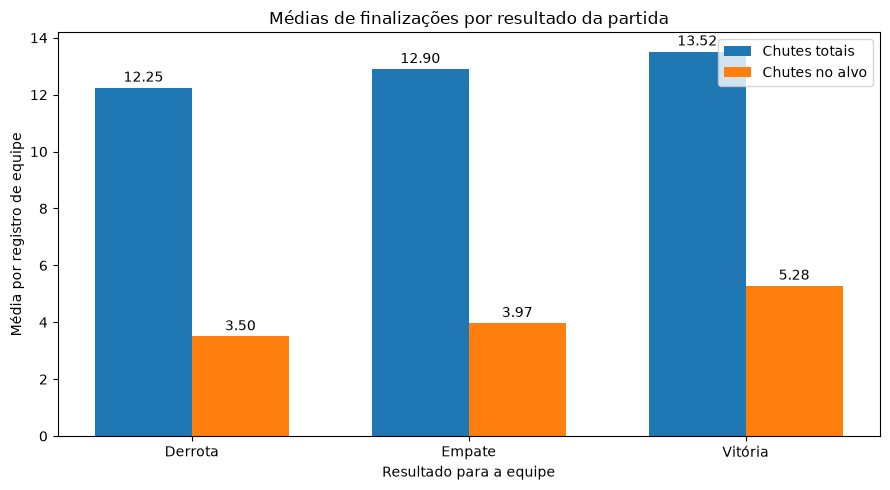

In [149]:
posicoes = np.arange(len(ordem_resultados))
largura = 0.35

valores_chutes = media_resultados["media_chutes"]
valores_alvo = media_resultados["media_chutes_no_alvo"]

plt.figure(figsize=(9, 5))

barras1 = plt.bar(
    posicoes - largura / 2,
    valores_chutes,
    largura,
    label="Chutes totais"
)

barras2 = plt.bar(
    posicoes + largura / 2,
    valores_alvo,
    largura,
    label="Chutes no alvo"
)

plt.bar_label(barras1, fmt="%.2f", padding=2)
plt.bar_label(barras2, fmt="%.2f", padding=2)

plt.xticks(posicoes, ordem_resultados)
plt.xlabel("Resultado para a equipe")
plt.ylabel("Média por registro de equipe")
plt.title("Médias de finalizações por resultado da partida")
plt.legend()
plt.tight_layout()
plt.show()

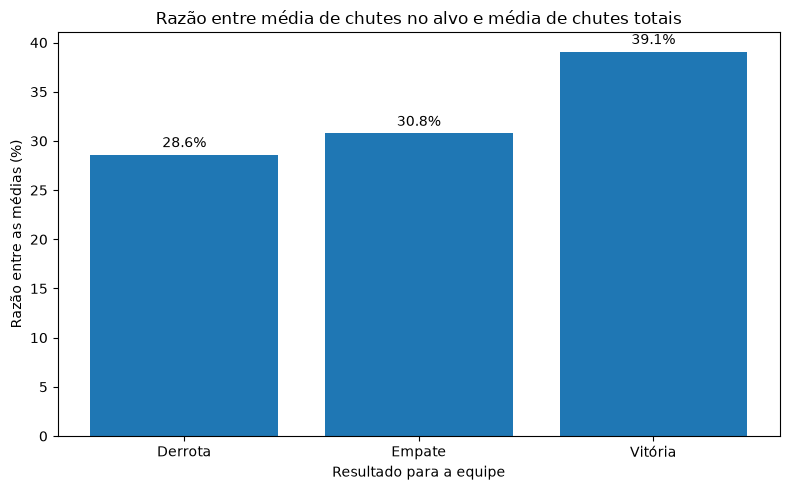

In [150]:
plt.figure(figsize=(8, 5))

barras = plt.bar(
    media_resultados.index,
    media_resultados["razao_medias_chutes_no_alvo"]
)

plt.bar_label(barras, fmt="%.1f%%", padding=3)
plt.xlabel("Resultado para a equipe")
plt.ylabel("Razão entre as médias (%)")
plt.title("Razão entre média de chutes no alvo e média de chutes totais")
plt.tight_layout()
plt.show()

### 6.3. Interpretação

Após a aplicação dos filtros de qualidade, a análise considera uma amostra de partidas dos anos de 2017 a 2023 e 2025, desconsiderando os registros de 2015 e 2016, que apresentaram proporções anormais de zeros nas estatísticas de chutes no alvo, além das partidas de 2019 em que ambas as equipes registraram zero chutes totais e zero chutes no alvo.

As médias de chutes totais e chutes no alvo são comparadas entre equipes que venceram, empataram ou perderam. Essa comparação permite observar a relação entre o volume de finalizações e os resultados das partidas, sem estabelecer uma relação de causalidade. Outros fatores, como postura tática, qualidade dos adversários e circunstâncias da partida, também podem influenciar essas estatísticas e seus resultados.

## 7. Síntese dos Resultados e Limitações

### Principais Achados

Esta seção reúne os resultados das análises anteriores. Execute o notebook de cima para baixo antes de atualizar os valores ou escrever a versão definitiva das interpretações.

In [151]:
print("PERÍODO COBERTO PELA BASE")
print(f"{df['ano'].min()} a {df['ano'].max()}")

print("\nTOTAL DE PARTIDAS")
print(f"{len(df):,}".replace(",", "."))

print("\nMÉDIA GERAL DE GOLS POR PARTIDA")
print(f"{df['gols_total'].mean():.2f}")

print("\nDISTRIBUIÇÃO GERAL DOS RESULTADOS (%)")
display((df["resultado"].value_counts(normalize=True) * 100).round(2))

print("\nTOP 5 — SALDO MÉDIO DE GOLS (MÍNIMO DE 100 PARTIDAS)")
display(
    equipes_filtradas.sort_values(
        "saldo_medio_gols",
        ascending=False
    )[["media_gols_marcados", "media_gols_sofridos", "saldo_medio_gols"]]
    .head(5)
    .round(3)
)

print("\nAMOSTRA DA ANÁLISE DE FINALIZAÇÕES")
print(f"Observações de equipes: {len(df_analise):,}".replace(",", "."))
display(df_analise["resultado"].value_counts())

PERÍODO COBERTO PELA BASE
2003 a 2025

TOTAL DE PARTIDAS
9.165

MÉDIA GERAL DE GOLS POR PARTIDA
2.56

DISTRIBUIÇÃO GERAL DOS RESULTADOS (%)


resultado
Vitória do Mandante     49.65
Empate                  26.42
Vitória do Visitante    23.94
Name: proportion, dtype: float64


TOP 5 — SALDO MÉDIO DE GOLS (MÍNIMO DE 100 PARTIDAS)


,media_gols_marcados,media_gols_sofridos,saldo_medio_gols
equipe,,,
Palmeiras,1.485,1.119,0.367
Sao Paulo,1.408,1.084,0.324
Flamengo,1.463,1.153,0.310
Cruzeiro,1.424,1.182,0.242
Internacional,1.329,1.104,0.225



AMOSTRA DA ANÁLISE DE FINALIZAÇÕES
Observações de equipes: 6.034


resultado
Derrota    2187
Vitória    2187
Empate     1660
Name: count, dtype: int64

### Limitações

- A qualidade das estatísticas de finalização varia entre temporadas. Os anos de 2015 e 2016 apresentam proporções muito elevadas de zeros em chutes no alvo.
- Em 2019, foram identificadas partidas em que ambas as equipes aparecem com zero chutes totais e zero chutes no alvo. Esses registros foram retirados da análise comparativa, mas devem permanecer documentados.
- A identificação de valores suspeitos não comprova, por si só, que a fonte original esteja errada. A confirmação depende de documentação ou validação externa.
- A análise histórica reúne equipes, formatos de competição e quantidades de partidas diferentes. Rankings por média reduzem o efeito da quantidade de jogos, mas não eliminam diferenças entre épocas.
- O limite mínimo de 100 partidas é uma decisão metodológica adotada para o ranking, e não uma regra universal.
- A relação entre finalizações e resultado é observacional e não demonstra causalidade.

### Conclusão Geral

A exploração dos dados permite observar padrões históricos de gols, resultados e desempenho das equipes no Campeonato Brasileiro. As análises por médias tornam as comparações entre clubes mais equilibradas do que a utilização exclusiva de totais acumulados.

A investigação das estatísticas de finalização também mostrou que a qualidade dos dados precisa ser considerada antes de interpretar os resultados. Em particular, os registros de 2015 e 2016 e determinadas partidas de 2019 apresentam sinais que justificam tratamento específico.

Após os filtros documentados, a comparação entre chutes e resultados pode indicar associações entre desempenho ofensivo e vitória, empate ou derrota. Essas associações devem ser interpretadas com cautela, considerando as limitações da base e sem estabelecer relações de causa e efeito.

### Reprodutibilidade e Próximos Passos

- Execute todas as células em ordem (`Kernel` → `Restart & Run All`).
- Confirme que não há erros de execução e que os resultados das tabelas e gráficos são atualizados.
- Mantenha os arquivos originais em `data/raw/` sem modificá-los.
- Registre no README a origem da base, o período coberto, as colunas utilizadas e as limitações encontradas.
- Se houver documentação adicional da fonte, valide os registros suspeitos antes de qualquer exclusão definitiva.